# Notebook 02 — Exploratory Data Analysis (EDA)

**Goal**: Visualize and understand the data before building any model.
EDA is non-negotiable in ML — models trained on poorly understood data almost always fail.

**What you'll learn:**
- Histograms — understand distributions
- Box plots — spot outliers
- Scatter plots — see relationships between features
- Correlation heatmap — which features move together

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Style settings
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

# Load data
df = pd.read_csv('../data/customers_raw.csv')

# Re-add engineered columns from notebook 01
df['spending_ratio'] = (df['monthly_spending'] / (df['annual_income'] / 12)).round(4)
df['savings_ratio']  = (df['savings_balance'] / df['annual_income']).round(4)

print(f'Loaded {len(df)} customers, {df.shape[1]} columns')

Loaded 1000 customers, 12 columns


## Step 1 — Distributions (Histograms)

A histogram shows how values are spread across a range.
- **Normal distribution** (bell curve) → most ML algorithms work best with this
- **Skewed** → may need log transform
- **Bimodal** (two peaks) → strong signal, possibly two groups

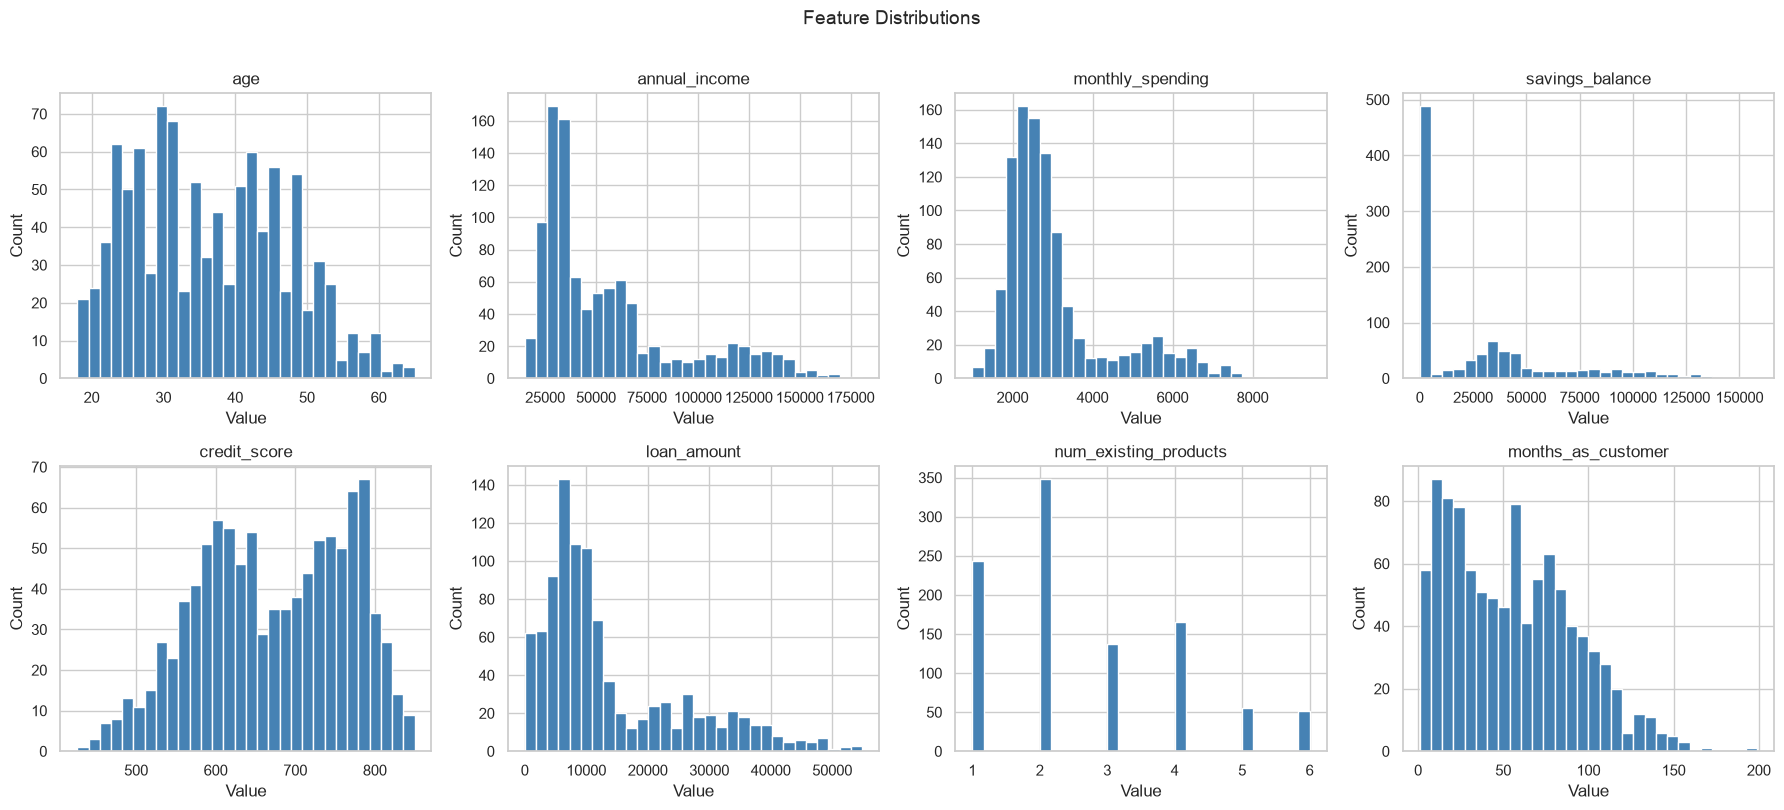

In [2]:
numeric_features = ['age', 'annual_income', 'monthly_spending',
                    'savings_balance', 'credit_score', 'loan_amount',
                    'num_existing_products', 'months_as_customer']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_features):
    axes[i].hist(df[col].dropna(), bins=30, edgecolor='white', color='steelblue')
    axes[i].set_title(col, fontsize=12)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Count')

plt.suptitle('Feature Distributions', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

**What to notice:**
- `annual_income` and `savings_balance` are right-skewed (long tail to the right)
- `credit_score` looks roughly normal
- `loan_amount` might be bimodal — some people have zero, others have high loans

## Step 2 — Box Plots (Outlier Detection)

A box plot shows:
- The box: 25th to 75th percentile (the middle 50% of data)
- The line in the box: median
- The whiskers: ~1.5x the box range
- **Dots beyond whiskers**: outliers

Outliers can mislead clustering — a single billionaire would skew the "High Earner" cluster massively.

/var/folders/2l/kcmxxtyn6wb983yx9y6tnf140000gn/T/ipykernel_90688/1523252693.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(df[col].dropna(), vert=True, patch_artist=True,
/var/folders/2l/kcmxxtyn6wb983yx9y6tnf140000gn/T/ipykernel_90688/1523252693.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(df[col].dropna(), vert=True, patch_artist=True,
/var/folders/2l/kcmxxtyn6wb983yx9y6tnf140000gn/T/ipykernel_90688/1523252693.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(df[col].dropna(), vert=True, patch_artist=True,
/var/folders/2l/kcmxxtyn6wb983yx9y6tnf140000gn/T/ipykernel_90688/1523252693.py:5: Mat

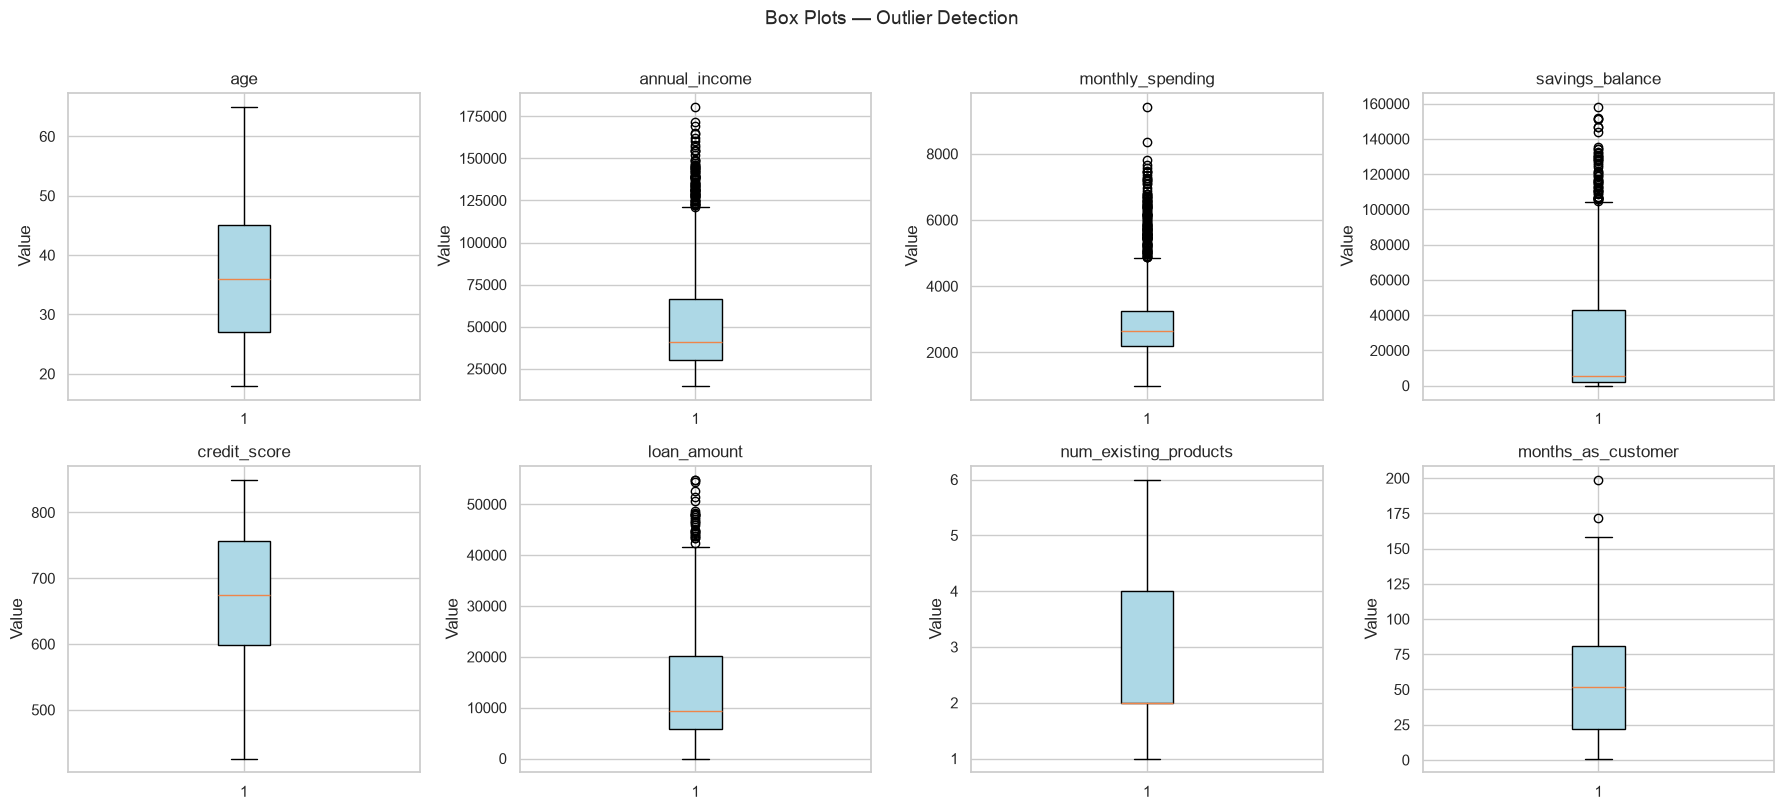

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_features):
    axes[i].boxplot(df[col].dropna(), vert=True, patch_artist=True,
                   boxprops=dict(facecolor='lightblue'))
    axes[i].set_title(col, fontsize=12)
    axes[i].set_ylabel('Value')

plt.suptitle('Box Plots — Outlier Detection', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [4]:
# Count outliers using IQR method
# IQR = Q3 - Q1 ; outlier = value < Q1 - 1.5*IQR  OR  value > Q3 + 1.5*IQR

print('Outlier count per feature (IQR method):')
for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]
    print(f'  {col:30s}: {len(outliers)} outliers ({len(outliers)/len(df)*100:.1f}%)')

Outlier count per feature (IQR method):
  age                           : 0 outliers (0.0%)
  annual_income                 : 88 outliers (8.8%)
  monthly_spending              : 140 outliers (14.0%)
  savings_balance               : 55 outliers (5.5%)
  credit_score                  : 0 outliers (0.0%)
  loan_amount                   : 29 outliers (2.9%)
  num_existing_products         : 0 outliers (0.0%)
  months_as_customer            : 2 outliers (0.2%)


## Step 3 — Scatter Plots (Feature Relationships)

Scatter plots show how two features relate to each other.
If we color by archetype, we can see whether our ML task is feasible — do the groups separate visually?

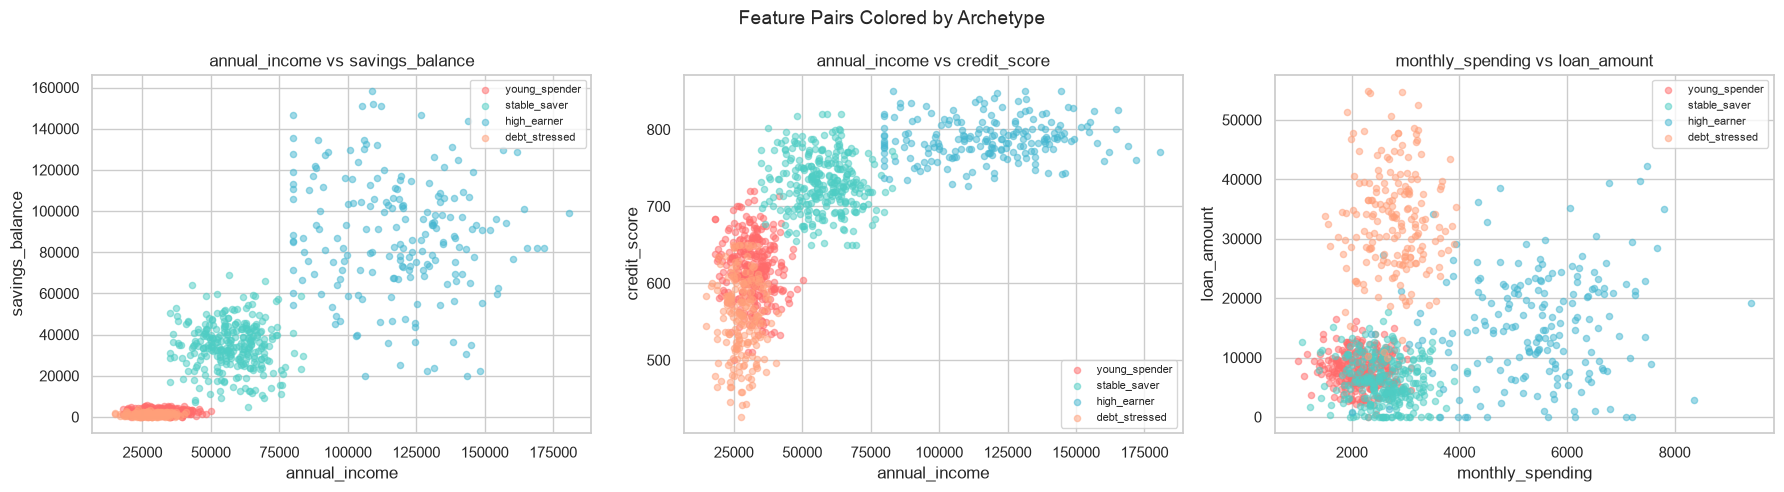

In [5]:
# Color map for archetypes
archetype_colors = {
    'young_spender': '#FF6B6B',
    'stable_saver':  '#4ECDC4',
    'high_earner':   '#45B7D1',
    'debt_stressed': '#FFA07A',
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

pairs = [
    ('annual_income', 'savings_balance'),
    ('annual_income', 'credit_score'),
    ('monthly_spending', 'loan_amount'),
]

for ax, (x_col, y_col) in zip(axes, pairs):
    for archetype, color in archetype_colors.items():
        subset = df[df['archetype'] == archetype]
        ax.scatter(subset[x_col], subset[y_col],
                   c=color, label=archetype, alpha=0.5, s=20)
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.set_title(f'{x_col} vs {y_col}')
    ax.legend(fontsize=8)

plt.suptitle('Feature Pairs Colored by Archetype', fontsize=14)
plt.tight_layout()
plt.show()

**What to notice:** The groups overlap a bit (noise is intentional). Our ML model will need to find these patterns without seeing the color labels.

## Step 4 — Correlation Heatmap

Correlation measures how much two features move together:
- **+1**: perfect positive correlation (one goes up, so does the other)
- **-1**: perfect negative correlation (one goes up, the other goes down)
- **0**: no linear relationship

High correlation between two features = they carry similar information (redundancy).

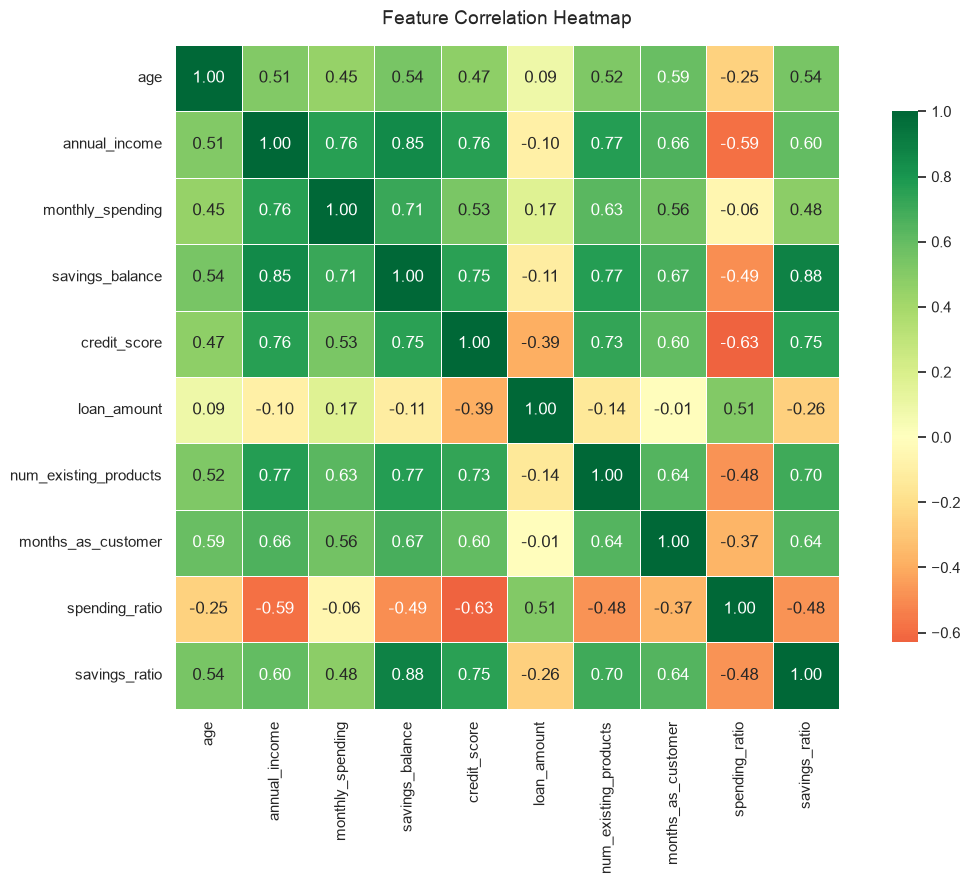

In [6]:
corr_cols = numeric_features + ['spending_ratio', 'savings_ratio']
corr_matrix = df[corr_cols].corr().round(2)

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)
plt.title('Feature Correlation Heatmap', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

In [7]:
# Print strong correlations (|r| > 0.4), excluding self-correlation
print('Strong correlations (|r| > 0.4):')
for col in corr_matrix.columns:
    for row in corr_matrix.index:
        if col != row:
            r = corr_matrix.loc[row, col]
            if abs(r) > 0.4 and row < col:  # avoid duplicates
                print(f'  {row:30s} <-> {col:30s} : {r:.2f}')

Strong correlations (|r| > 0.4):
  age                            <-> annual_income                  : 0.51
  age                            <-> monthly_spending               : 0.45
  annual_income                  <-> monthly_spending               : 0.76
  credit_score                   <-> monthly_spending               : 0.53
  age                            <-> savings_balance                : 0.54
  annual_income                  <-> savings_balance                : 0.85
  monthly_spending               <-> savings_balance                : 0.71
  credit_score                   <-> savings_balance                : 0.75
  num_existing_products          <-> savings_balance                : 0.77
  months_as_customer             <-> savings_balance                : 0.67
  age                            <-> credit_score                   : 0.47
  annual_income                  <-> credit_score                   : 0.76
  age                            <-> num_existing_products         

## Step 5 — Distribution by Archetype (Violin Plots)

A violin plot is like a box plot but also shows the full distribution shape.
Here we check how `annual_income` and `credit_score` differ across archetypes.

/var/folders/2l/kcmxxtyn6wb983yx9y6tnf140000gn/T/ipykernel_90688/3700235472.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='archetype', y='annual_income',
/var/folders/2l/kcmxxtyn6wb983yx9y6tnf140000gn/T/ipykernel_90688/3700235472.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='archetype', y='credit_score',


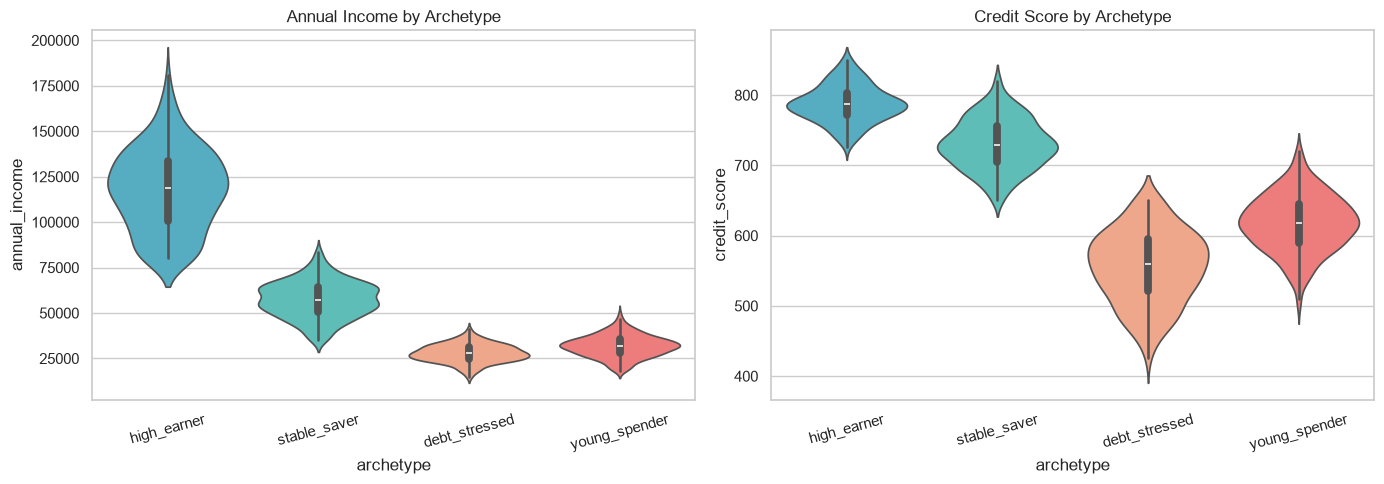

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.violinplot(data=df, x='archetype', y='annual_income',
               palette=archetype_colors, ax=axes[0])
axes[0].set_title('Annual Income by Archetype')
axes[0].tick_params(axis='x', rotation=15)

sns.violinplot(data=df, x='archetype', y='credit_score',
               palette=archetype_colors, ax=axes[1])
axes[1].set_title('Credit Score by Archetype')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## EDA Summary

What we learned about our data:

| Finding | Implication for ML |
|---|---|
| Income & savings are right-skewed | May benefit from log transform |
| Some outliers in income/loans | Need robust scaling or clipping |
| Groups overlap in raw feature space | PCA + clustering still needed |
| Spending ratio & savings ratio are useful | Good engineered features |
| Annual income & savings are correlated | PCA will help reduce redundancy |

**Next up: Notebook 03 — Preprocessing**
We'll handle missing values, scale features, and prepare the data for ML.